<a href="https://colab.research.google.com/github/Dudab2/Ciencia_de_Dados_Aprendizagem_da_Maquina/blob/main/Projeto_Adesao_Medicamentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Adesão à medicação em idosos — CRISP-DM

Disciplina: Ciência de Dados e Aprendizagem de Máquina | Docente: Profa. Kadidja Valéria

Os dados são **sintéticos** (não são de pessoas reais) e foram criados para fins didáticos.
Cada fase do CRISP-DM abaixo segue o checklist do Guia Prático da disciplina. Execute as células em ordem.

## Preparação do ambiente
Bibliotecas e carregamento do arquivo `idosos_medicacao.csv`.

In [1]:
import os, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix

CAMINHO = 'idosos_medicacao.csv'
if not os.path.exists(CAMINHO):
    from google.colab import files
    enviado = files.upload()
    CAMINHO = list(enviado.keys())[0]
print('Arquivo carregado:', CAMINHO)

Arquivo carregado: idosos_medicacao.csv


# Fase 1: Entendimento do Negócio

**Objetivo de negócio.** Reduzir o esquecimento de doses de remédio entre idosos, identificando quem tem baixa adesão e por quê, para que cuidadores e equipes de saúde atuem primeiro nesse grupo.

**Perguntas do projeto**
1. Que porcentagem dos idosos esquece de tomar doses?
2. Quais características aumentam o risco de baixa adesão?

**Definição de baixa adesão:** esquecer 20% ou mais das doses prescritas na semana (escolha do projeto).

**Critérios de sucesso** (definidos neste projeto)
- O modelo deve ter AUC de pelo menos 0,80.
- O modelo deve encontrar pelo menos 70% dos idosos com baixa adesão (recall ≥ 0,70), pois deixar um caso de risco passar é pior do que um alarme falso.
- As duas perguntas devem ser respondidas com números.

**Avaliação da situação**

| Item | Situação |
|---|---|
| Recursos | Base `idosos_medicacao.csv`, Python (pandas, scikit-learn), Google Colab, uma pessoa no projeto |
| Riscos | Dados sintéticos (não valem como evidência clínica); poucos casos de baixa adesão (classe desbalanceada); dados com erros de digitação |
| Custo-benefício | Custo baixo (ferramentas gratuitas, poucas horas); benefício potencial é priorizar o acompanhamento de quem mais precisa |

**Metas técnicas de mineração de dados**
- Meta 1: calcular a taxa de esquecimento de cada idoso e a porcentagem geral (pergunta 1).
- Meta 2: comparar grupos e treinar um classificador de baixa adesão (pergunta 2).

**Plano de projeto**

| Fase | Atividade | Entrega |
|---|---|---|
| 1 | Definir objetivos, critérios e metas | Esta seção |
| 2 | Explorar e checar qualidade dos dados | Tabelas e gráficos |
| 3 | Limpar e criar atributos | Base limpa |
| 4 | Treinar e comparar modelos | Modelo escolhido |
| 5 | Avaliar pelos critérios de negócio | Decisão |
| 6 | Plano de implementação e monitoramento, relatório, lições | Arquivos finais |

In [2]:
LIMITE_BAIXA_ADESAO = 0.20
META_AUC = 0.80
META_RECALL = 0.70
print('Baixa adesão = taxa de esquecimento >=', LIMITE_BAIXA_ADESAO)
print('Meta AUC >=', META_AUC, '| Meta recall >=', META_RECALL)

Baixa adesão = taxa de esquecimento >= 0.2
Meta AUC >= 0.8 | Meta recall >= 0.7


# Fase 2: Entendimento dos Dados

Checklist: coletar dados iniciais, descrever quantidade e qualidade, explorar e verificar qualidade.

## 2.1 Coleta e descrição
Fonte única: `idosos_medicacao.csv` (dados sintéticos, criados pelo grupo a partir de uma pesquisa da SciELO).

In [3]:
bruto = pd.read_csv(CAMINHO)
print('Linhas e colunas:', bruto.shape)
bruto.head()

Linhas e colunas: (1545, 14)


,id_paciente,idade,sexo,escolaridade,mora_sozinho,tem_cuidador,usa_alarme,n_doencas_cronicas,n_medicamentos,comprometimento_cognitivo,doses_prescritas_semana,doses_esquecidas_semana,horario_mais_esquecido,data_cadastro
0,P1496,65,M,Sem escolaridade,NÃO,não,Sim,5,7.0,Nenhum,56,3,Noite,2024-08-03
1,P0544,setenta e três,F,medio,Sim,SIM,Não,1,2.0,Nenhum,14,0,Nenhum,2025-06-05
2,P1269,79,F,Superior,Sim,Sim,não,1,5.0,Nenhum,49,7,Noite,2024-05-15
3,P0529,76,F,Médio,Não,Não,Sim,2,3.0,Nenhum,28,2,Manhã,2025-01-17
4,P1095,69,feminino,Ensino Fundamental,Sim,Não,Sim,1,1.0,Nenhum,14,0,Nenhum,2024-03-17


In [4]:
pd.DataFrame({'tipo': bruto.dtypes.astype(str), 'ausentes': bruto.isna().sum(), '% ausentes': (bruto.isna().mean()*100).round(1)})

,tipo,ausentes,% ausentes
id_paciente,object,0,0.0
idade,object,57,3.7
sexo,object,0,0.0
escolaridade,object,112,7.2
mora_sozinho,object,0,0.0
tem_cuidador,object,0,0.0
usa_alarme,object,0,0.0
n_doencas_cronicas,int64,0,0.0
n_medicamentos,float64,47,3.0
comprometimento_cognitivo,object,0,0.0


## 2.2 Verificação de qualidade
Procurando erros, duplicatas e inconsistências.

In [5]:
print('Linhas duplicadas:', bruto.duplicated().sum())
print()
for col in ['sexo', 'escolaridade', 'mora_sozinho', 'tem_cuidador', 'usa_alarme']:
    print(col, '->', sorted(bruto[col].dropna().astype(str).unique()))
    print()
print('Idades escritas por extenso:', bruto['idade'].astype(str).str.contains('[a-zA-Z]').sum())
d = bruto['data_cadastro'].dropna().astype(str)
print('Datas no formato AAAA-MM-DD:', d.str.contains('-').sum(), '| no formato DD/MM/AAAA:', d.str.contains('/').sum())

Linhas duplicadas: 45

sexo -> ['F', 'FEMININO', 'Feminino', 'M', 'Masculino', 'f', 'feminino', 'm', 'masculino']

escolaridade -> ['Analfabeto', 'Ensino Fundamental', 'Ensino Médio', 'Ensino Superior', 'FUNDAMENTAL', 'Fundamental', 'Médio', 'Médio ', 'SUPERIOR', 'Sem escolaridade', 'Superior', 'fundamental', 'medio', 'nenhuma', 'sem escolaridade', 'superior']

mora_sozinho -> ['N', 'Nao', 'NÃO', 'Não', 'S', 'SIM', 'Sim', 'Sim ', 'nao', 'não', 's', 'sim']

tem_cuidador -> ['-', '?', 'N', 'Nao', 'NÃO', 'Não', 'S', 'SIM', 'Sim', 'Sim ', 'ignorado', 'nao', 'não', 's', 'sim']

usa_alarme -> ['N', 'Nao', 'NÃO', 'Não', 'S', 'SIM', 'Sim', 'Sim ', 'nao', 'não', 's', 'sim']

Idades escritas por extenso: 103
Datas no formato AAAA-MM-DD: 1099 | no formato DD/MM/AAAA: 429


In [6]:
num = bruto.copy()
num['idade_num'] = pd.to_numeric(num['idade'], errors='coerce')
print('Idade mínima/máxima (só numéricas):', num['idade_num'].min(), '/', num['idade_num'].max())
print('n_medicamentos mínimo/máximo:', bruto['n_medicamentos'].min(), '/', bruto['n_medicamentos'].max())
incoerentes = (bruto['doses_esquecidas_semana'] < 0) | (bruto['doses_esquecidas_semana'] > bruto['doses_prescritas_semana'])
print('Registros com doses esquecidas negativas ou maiores que as prescritas:', int(incoerentes.sum()))

Idade mínima/máxima (só numéricas): -1.0 / 999.0
n_medicamentos mínimo/máximo: 1.0 / 99.0
Registros com doses esquecidas negativas ou maiores que as prescritas: 22


## 2.3 Exploração inicial e hipóteses
Hipóteses a testar nas próximas fases: morar sozinho, não ter cuidador, ter comprometimento cognitivo e tomar muitos remédios aumentam o esquecimento; usar alarme e ter cuidador diminuem.

In [7]:
bruto[['n_doencas_cronicas', 'n_medicamentos', 'doses_prescritas_semana', 'doses_esquecidas_semana']].describe().round(1)

,n_doencas_cronicas,n_medicamentos,doses_prescritas_semana,doses_esquecidas_semana
count,1545.0,1498.0,1545.0,1545.0
mean,2.0,3.6,31.6,3.1
std,1.2,5.8,16.8,5.2
min,1.0,1.0,7.0,-1.0
25%,1.0,2.0,21.0,0.0
50%,2.0,3.0,28.0,2.0
75%,3.0,4.0,42.0,4.0
max,8.0,99.0,119.0,63.0


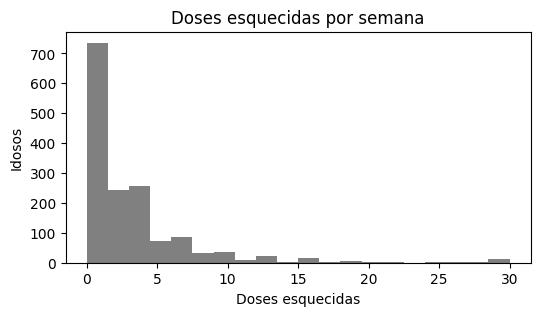

In [8]:
plt.figure(figsize=(6, 3))
bruto['doses_esquecidas_semana'].clip(0, 30).plot(kind='hist', bins=20, color='gray')
plt.title('Doses esquecidas por semana')
plt.xlabel('Doses esquecidas')
plt.ylabel('Idosos')
plt.show()

# Fase 3: Preparação dos Dados

Checklist: **Selecionar → Limpar → Construir → Integrar**.

- **Selecionar:** todas as colunas são úteis; `id_paciente` não entra no modelo.
- **Limpar:** remover duplicatas, padronizar categorias, converter idades por extenso, tratar valores absurdos como ausentes e remover registros incoerentes.
- **Construir:** criar `taxa_esquecimento`, `esquece_alguma` e `baixa_adesao`.
- **Integrar:** não se aplica, pois existe uma única tabela.
- **Atributos sensíveis:** a base não tem dados pessoais identificáveis (nome, documento ou cartão); apenas um código de paciente.

In [9]:
def norm(x):
    return unicodedata.normalize('NFKD', str(x).strip().lower()).encode('ascii', 'ignore').decode()

def sim_nao(x):
    if pd.isna(x): return np.nan
    return {'sim': 1, 's': 1, 'nao': 0, 'n': 0}.get(norm(x), np.nan)

def escolaridade(x):
    if pd.isna(x): return np.nan
    s = norm(x)
    if 'anal' in s or 'sem' in s or 'nenhuma' in s: return 'Sem escolaridade'
    if 'fund' in s: return 'Fundamental'
    if 'med' in s: return 'Médio'
    if 'sup' in s: return 'Superior'
    return np.nan

DEZENAS = {'sessenta': 60, 'setenta': 70, 'oitenta': 80, 'noventa': 90}
UNIDADES = {'um': 1, 'dois': 2, 'tres': 3, 'quatro': 4, 'cinco': 5, 'seis': 6, 'sete': 7, 'oito': 8, 'nove': 9}

def idade(x):
    if pd.isna(x): return np.nan
    s = norm(x)
    m = re.search(r'\d+', s)
    if m:
        v = int(m.group())
    else:
        partes = s.split(' e ')
        v = DEZENAS.get(partes[0].strip(), np.nan)
        if len(partes) > 1 and v == v:
            v += UNIDADES.get(partes[1].strip(), 0)
    return v if 55 <= v <= 105 else np.nan

df = bruto.drop_duplicates().copy()
n_duplicatas = len(bruto) - len(df)

for c in ['mora_sozinho', 'tem_cuidador', 'usa_alarme']:
    df[c] = df[c].map(sim_nao)
df['sexo'] = df['sexo'].str.strip().str.lower().str[0].str.upper()
df['escolaridade'] = df['escolaridade'].map(escolaridade)
df['idade'] = df['idade'].map(idade)
df['n_medicamentos'] = df['n_medicamentos'].where(df['n_medicamentos'] <= 20)
df['data_cadastro'] = pd.to_datetime(df['data_cadastro'], format='mixed', errors='coerce')

incoerentes = (df['doses_esquecidas_semana'] < 0) | (df['doses_esquecidas_semana'] > df['doses_prescritas_semana'])
n_incoerentes = int(incoerentes.sum())
df = df[~incoerentes].copy()

df['taxa_esquecimento'] = (df['doses_esquecidas_semana'] / df['doses_prescritas_semana']).round(4)
df['esquece_alguma'] = (df['doses_esquecidas_semana'] > 0).astype(int)
df['baixa_adesao'] = (df['taxa_esquecimento'] >= LIMITE_BAIXA_ADESAO).astype(int)

print('Linhas originais:', len(bruto))
print('Duplicatas removidas:', n_duplicatas)
print('Registros incoerentes removidos:', n_incoerentes)
print('Linhas após a limpeza:', len(df))

Linhas originais: 1545
Duplicatas removidas: 45
Registros incoerentes removidos: 21
Linhas após a limpeza: 1479


In [10]:
for col in ['sexo', 'escolaridade', 'mora_sozinho', 'tem_cuidador', 'usa_alarme']:
    print(col, '->', sorted(df[col].dropna().unique()))
print()
print('Ausentes após a limpeza:')
df.isna().sum()[df.isna().sum() > 0]

sexo -> ['F', 'M']
escolaridade -> ['Fundamental', 'Médio', 'Sem escolaridade', 'Superior']
mora_sozinho -> [np.int64(0), np.int64(1)]
tem_cuidador -> [np.float64(0.0), np.float64(1.0)]
usa_alarme -> [np.int64(0), np.int64(1)]

Ausentes após a limpeza:


,0
idade,62
escolaridade,104
tem_cuidador,26
n_medicamentos,52
data_cadastro,16


In [11]:
df.to_csv('idosos_medicacao_limpo.csv', index=False)
df.head()

,id_paciente,idade,sexo,escolaridade,mora_sozinho,tem_cuidador,usa_alarme,n_doencas_cronicas,n_medicamentos,comprometimento_cognitivo,doses_prescritas_semana,doses_esquecidas_semana,horario_mais_esquecido,data_cadastro,taxa_esquecimento,esquece_alguma,baixa_adesao
0,P1496,65.0,M,Sem escolaridade,0,0.0,1,5,7.0,Nenhum,56,3,Noite,2024-08-03,0.0536,1,0
1,P0544,73.0,F,Médio,1,1.0,0,1,2.0,Nenhum,14,0,Nenhum,2025-06-05,0.0000,0,0
2,P1269,79.0,F,Superior,1,1.0,0,1,5.0,Nenhum,49,7,Noite,2024-05-15,0.1429,1,0
3,P0529,76.0,F,Médio,0,0.0,1,2,3.0,Nenhum,28,2,Manhã,2025-01-17,0.0714,1,0
4,P1095,69.0,F,Fundamental,1,0.0,1,1,1.0,Nenhum,14,0,Nenhum,2024-03-17,0.0000,0,0


## Respostas às perguntas do projeto (Metas técnicas 1 e 2)

In [12]:
N = len(df)
print('PERGUNTA 1: quantos idosos esquecem doses?')
print(f"- Esquecem pelo menos uma dose na semana: {df.esquece_alguma.mean()*100:.1f}%")
print(f"- Baixa adesão (20% ou mais das doses): {df.baixa_adesao.mean()*100:.1f}%")
print(f"- Média de doses esquecidas: {df.taxa_esquecimento.mean()*100:.1f}%")
h = df[df.horario_mais_esquecido != 'Nenhum'].horario_mais_esquecido.value_counts(normalize=True) * 100
print('- Horário mais esquecido (entre quem esquece):')
print(h.round(1).to_string())

PERGUNTA 1: quantos idosos esquecem doses?
- Esquecem pelo menos uma dose na semana: 73.2%
- Baixa adesão (20% ou mais das doses): 7.5%
- Média de doses esquecidas: 7.7%
- Horário mais esquecido (entre quem esquece):
horario_mais_esquecido
Noite    43.8
Tarde    31.6
Manhã    24.7


In [13]:
df['faixa_idade'] = pd.cut(df.idade, [54, 69, 79, 105], labels=['60-69', '70-79', '80+'])
df['faixa_meds'] = pd.cut(df.n_medicamentos, [0, 2, 4, 6, 20], labels=['1-2', '3-4', '5-6', '7+'])
df['fatores_risco'] = (df.mora_sozinho == 1).astype(int) + (df.tem_cuidador == 0).astype(int) + (df.comprometimento_cognitivo != 'Nenhum').astype(int)

print('PERGUNTA 2: % de baixa adesão por característica')
tabelas = []
for col in ['mora_sozinho', 'tem_cuidador', 'usa_alarme', 'comprometimento_cognitivo', 'faixa_idade', 'faixa_meds', 'escolaridade', 'sexo']:
    t = df.groupby(col, observed=True).baixa_adesao.agg(['size', 'mean'])
    t['mean'] = (t['mean'] * 100).round(1)
    t.columns = ['idosos', '% baixa adesão']
    t.index = [f'{col} = {i}' for i in t.index]
    tabelas.append(t)
pd.concat(tabelas)

PERGUNTA 2: % de baixa adesão por característica


,idosos,% baixa adesão
mora_sozinho = 0,1100,3.2
mora_sozinho = 1,379,20.1
tem_cuidador = 0.0,771,12.3
tem_cuidador = 1.0,682,2.3
usa_alarme = 0,985,10.2
usa_alarme = 1,494,2.2
comprometimento_cognitivo = Leve,206,17.0
comprometimento_cognitivo = Moderado,111,30.6
comprometimento_cognitivo = Nenhum,1162,3.6
faixa_idade = 60-69,399,1.5


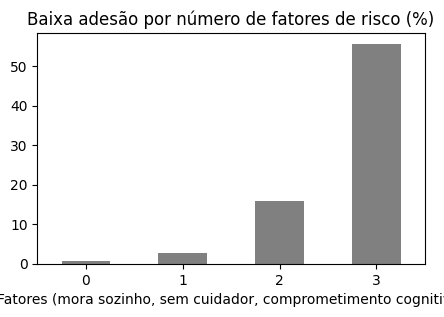

,baixa_adesao
fatores_risco,
0,0.6
1,2.6
2,15.9
3,55.7


In [14]:
r = df.groupby('fatores_risco').baixa_adesao.mean() * 100
plt.figure(figsize=(5, 3))
r.plot(kind='bar', color='gray')
plt.title('Baixa adesão por número de fatores de risco (%)')
plt.xlabel('Fatores (mora sozinho, sem cuidador, comprometimento cognitivo)')
plt.xticks(rotation=0)
plt.show()
r.round(1)

# Fase 4: Modelagem

Checklist: selecionar técnicas, gerar design de teste, construir e iterar, avaliar tecnicamente.

**Técnicas escolhidas:** regressão logística (simples e explicável: os coeficientes mostram quais fatores aumentam o risco) e árvore de decisão (captura relações não lineares). Ambas usam `class_weight='balanced'`, pois a baixa adesão é a classe rara.

**Design de teste:** 70% treino e 30% teste, com estratificação. A escolha dos parâmetros usa validação cruzada (5 partes) só no treino, e o teste é usado uma única vez no final.

In [15]:
colunas = ['idade', 'n_medicamentos', 'n_doencas_cronicas', 'mora_sozinho', 'tem_cuidador', 'usa_alarme']
X = df[colunas].copy()
X['cognicao_leve'] = (df.comprometimento_cognitivo == 'Leve').astype(int)
X['cognicao_moderada'] = (df.comprometimento_cognitivo == 'Moderado').astype(int)
y = df['baixa_adesao']

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
print('Treino:', len(Xtr), '| Teste:', len(Xte))
print('% baixa adesão no treino:', round(ytr.mean()*100, 1), '| no teste:', round(yte.mean()*100, 1))

Treino: 1035 | Teste: 444
% baixa adesão no treino: 7.5 | no teste: 7.4


In [16]:
candidatos = {}
for C in [0.01, 0.1, 1, 10]:
    candidatos[f'Regressão logística C={C}'] = make_pipeline(
        SimpleImputer(strategy='median'), StandardScaler(),
        LogisticRegression(C=C, class_weight='balanced', max_iter=1000))
for d in [3, 5, 7]:
    candidatos[f'Árvore max_depth={d}'] = make_pipeline(
        SimpleImputer(strategy='median'),
        DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42))

resultados = []
for nome, modelo in candidatos.items():
    auc_cv = cross_val_score(modelo, Xtr, ytr, cv=5, scoring='roc_auc').mean()
    resultados.append((nome, round(auc_cv, 3)))
tab_cv = pd.DataFrame(resultados, columns=['Modelo', 'AUC (validação cruzada)']).sort_values('AUC (validação cruzada)', ascending=False)
melhor_nome = tab_cv.iloc[0]['Modelo']
print('Melhor modelo na validação cruzada:', melhor_nome)
tab_cv

Melhor modelo na validação cruzada: Regressão logística C=0.1


,Modelo,AUC (validação cruzada)
1,Regressão logística C=0.1,0.918
0,Regressão logística C=0.01,0.917
2,Regressão logística C=1,0.917
3,Regressão logística C=10,0.916
4,Árvore max_depth=3,0.831
5,Árvore max_depth=5,0.809
6,Árvore max_depth=7,0.757


In [17]:
modelo_final = candidatos[melhor_nome].fit(Xtr, ytr)
prob = modelo_final.predict_proba(Xte)[:, 1]
pred = modelo_final.predict(Xte)

auc_teste = roc_auc_score(yte, prob)
recall_teste = recall_score(yte, pred)
precisao_teste = precision_score(yte, pred)
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()

print(f'AUC no teste: {auc_teste:.3f}')
print(f'Recall (baixa adesão): {recall_teste:.3f}')
print(f'Precisão (baixa adesão): {precisao_teste:.3f}')
print()
print('Matriz de confusão (teste):')
pd.DataFrame([[tn, fp], [fn, tp]], index=['real: adesão ok', 'real: baixa adesão'], columns=['previsto: ok', 'previsto: baixa'])

AUC no teste: 0.918
Recall (baixa adesão): 0.788
Precisão (baixa adesão): 0.277

Matriz de confusão (teste):


,previsto: ok,previsto: baixa
real: adesão ok,343,68
real: baixa adesão,7,26


In [18]:
if 'Regressão' in melhor_nome:
    coef = modelo_final[-1].coef_[0]
    imp = pd.Series(np.exp(coef), index=X.columns).sort_values(ascending=False).round(2)
    print('Razão de chances (acima de 1 aumenta o risco, abaixo de 1 protege):')
else:
    imp = pd.Series(modelo_final[-1].feature_importances_, index=X.columns).sort_values(ascending=False).round(2)
    print('Importância de cada variável na árvore:')
imp

Razão de chances (acima de 1 aumenta o risco, abaixo de 1 protege):


,0
cognicao_moderada,2.14
mora_sozinho,2.13
idade,1.93
cognicao_leve,1.86
n_medicamentos,1.24
n_doencas_cronicas,1.17
tem_cuidador,0.52
usa_alarme,0.37


# Fase 5: Avaliação

Aqui os resultados são medidos pelos **critérios de negócio da Fase 1**, e não só pela precisão técnica.

In [19]:
avaliacao = pd.DataFrame({
    'Critério (Fase 1)': ['AUC >= ' + str(META_AUC), 'Recall >= ' + str(META_RECALL), 'Duas perguntas respondidas com números'],
    'Resultado': [round(auc_teste, 3), round(recall_teste, 3), 'Sim (seção de respostas na Fase 3)'],
    'Atingido?': ['Sim' if auc_teste >= META_AUC else 'Não', 'Sim' if recall_teste >= META_RECALL else 'Não', 'Sim']
})
avaliacao

,Critério (Fase 1),Resultado,Atingido?
0,AUC >= 0.8,0.918,Sim
1,Recall >= 0.7,0.788,Sim
2,Duas perguntas respondidas com números,Sim (seção de respostas na Fase 3),Sim


In [20]:
total_risco = int(tp + fn)
alertas = int(tp + fp)
print(f'Idosos de teste: {len(yte)} | com baixa adesão de fato: {total_risco}')
print(f'O modelo emitiu {alertas} alertas e acertou {int(tp)} casos de risco (de {total_risco}).')
print(f'Para achar cada caso real, a equipe precisaria verificar cerca de {alertas/tp:.1f} idosos.')
print(f'Casos de risco que passariam despercebidos: {int(fn)}')

Idosos de teste: 444 | com baixa adesão de fato: 33
O modelo emitiu 94 alertas e acertou 26 casos de risco (de 33).
Para achar cada caso real, a equipe precisaria verificar cerca de 3.6 idosos.
Casos de risco que passariam despercebidos: 7


In [21]:
metas_ok = (auc_teste >= META_AUC) and (recall_teste >= META_RECALL)
if metas_ok:
    decisao = 'IMPLEMENTAR como ferramenta de triagem (apoia a equipe, não substitui o julgamento).'
else:
    decisao = 'ITERAR: voltar às Fases 3 e 4 (novos atributos ou parâmetros).'
print('Decisão:', decisao)

Decisão: IMPLEMENTAR como ferramenta de triagem (apoia a equipe, não substitui o julgamento).


**Revisão de falhas do processo**
- A baixa adesão é rara, então a precisão do modelo é baixa: ele gera muitos alarmes falsos. Isso é aceitável para triagem, mas deve ser considerado antes de usar na prática.
- Cognição, idade e número de medicamentos andam juntos, então as comparações simples não separam o efeito de cada fator.
- O limite de 20% foi uma escolha do projeto; outro limite mudaria os números.
- Os dados são sintéticos: os resultados valem só para este exercício.

**Nova pergunta (que volta ao ciclo):** o modelo funcionaria em dados reais de outra região ou período? Seria preciso coletar dados reais e repetir as Fases 2 a 5.

# Fase 6: Implementação

Entregáveis: plano de implementação, plano de monitoramento, relatório final e revisão do projeto.

## 6.1 Plano de implementação (arquitetura)

| Etapa | O que fazer | Quem |
|---|---|---|
| 1 | Salvar o modelo treinado (`modelo_adesao.joblib`) | Cientista de dados |
| 2 | Disponibilizar a função de previsão (abaixo) para a equipe de saúde, em planilha ou painel | Desenvolvedor |
| 3 | Preencher os dados do idoso (idade, remédios, doenças, mora sozinho, cuidador, alarme, cognição) e obter a probabilidade de baixa adesão | Equipe de saúde / cuidadores |
| 4 | Priorizar o acompanhamento de quem tem probabilidade alta (sugerir cuidador ou alarme) | Equipe de saúde |

In [22]:
joblib.dump(modelo_final, 'modelo_adesao.joblib')

def prever_risco(idade, n_medicamentos, n_doencas_cronicas, mora_sozinho, tem_cuidador, usa_alarme, cognicao='Nenhum'):
    linha = pd.DataFrame([{
        'idade': idade, 'n_medicamentos': n_medicamentos, 'n_doencas_cronicas': n_doencas_cronicas,
        'mora_sozinho': mora_sozinho, 'tem_cuidador': tem_cuidador, 'usa_alarme': usa_alarme,
        'cognicao_leve': int(cognicao == 'Leve'), 'cognicao_moderada': int(cognicao == 'Moderado')}])
    return float(joblib.load('modelo_adesao.joblib').predict_proba(linha[X.columns])[0, 1])

print('Exemplo 1 (mora sozinho, sem cuidador, sem alarme, cognição moderada):',
      round(prever_risco(84, 8, 4, 1, 0, 0, 'Moderado'), 2))
print('Exemplo 2 (mora acompanhado, com cuidador e alarme, sem comprometimento):',
      round(prever_risco(68, 2, 1, 0, 1, 1, 'Nenhum'), 2))

Exemplo 1 (mora sozinho, sem cuidador, sem alarme, cognição moderada): 0.99
Exemplo 2 (mora acompanhado, com cuidador e alarme, sem comprometimento): 0.0


## 6.2 Plano de monitoramento (obsolescência do modelo)

- **Frequência:** reavaliar o modelo a cada 6 meses ou a cada novo lote de dados.
- **O que medir:** AUC e recall em dados novos, comparados às metas da Fase 1.
- **Quando agir:** se AUC < 0,80 ou recall < 0,70, o modelo está obsoleto: voltar às Fases 3 e 4 e retreinar.
- **Também observar:** mudança no perfil dos idosos (idade média, % que mora sozinho), pois isso pode tornar o modelo menos confiável.

In [23]:
def monitorar(X_novo, y_novo):
    p = modelo_final.predict_proba(X_novo)[:, 1]
    auc = roc_auc_score(y_novo, p)
    rec = recall_score(y_novo, modelo_final.predict(X_novo))
    print(f'AUC: {auc:.3f} (meta {META_AUC}) | Recall: {rec:.3f} (meta {META_RECALL})')
    if auc < META_AUC or rec < META_RECALL:
        print('ALERTA: modelo abaixo das metas. Retreinar (voltar às Fases 3 e 4).')
    else:
        print('OK: modelo dentro das metas.')

monitorar(Xte.iloc[: len(Xte) // 2], yte.iloc[: len(yte) // 2])

AUC: 0.900 (meta 0.8) | Recall: 0.778 (meta 0.7)
OK: modelo dentro das metas.


## 6.3 Relatório final

- **Problema:** idosos esquecem doses de remédio e a equipe precisa saber quem priorizar.
- **Dados:** base sintética com limpeza de duplicatas, categorias inconsistentes, idades por extenso e registros incoerentes (ver Fase 3).
- **Resposta 1:** a maioria dos idosos esquece pelo menos uma dose por semana, mas só uma pequena parcela tem baixa adesão (números exatos na seção de respostas).
- **Resposta 2:** o risco cresce com o número de fatores (morar sozinho, não ter cuidador, ter comprometimento cognitivo); cuidador e alarme protegem.
- **Modelo:** escolhido por validação cruzada e avaliado uma vez no teste, com resultados comparados às metas da Fase 5.
- **Decisão:** ver a célula de decisão da Fase 5.

## 6.4 Revisão do projeto (lições aprendidas)

- Definir critérios de sucesso no início facilitou a avaliação final.
- A preparação dos dados foi a fase mais trabalhosa, como o guia prevê (50% a 70% do esforço).
- Comparar mais de um modelo evitou escolher a técnica sem justificativa.
- Voltar a fases anteriores é parte do método: aqui, a precisão baixa indica que novos atributos ou dados reais ajudariam.
- Documentar cada fase tornou o trabalho mais fácil de reproduzir.

## Iterações registradas
1. Exploração (Fase 2) mostrou erros de digitação e idades por extenso, o que levou a voltar e criar as funções de limpeza (Fase 3).
2. Um único modelo não justificava a escolha da técnica, então a Fase 4 passou a comparar duas técnicas e vários parâmetros.

# Verificação final

Confere item por item se o trabalho cumpre o checklist do Guia Prático CRISP-DM. Cada linha mostra OK ou FALHOU.

In [24]:
verificacoes = [
    # Fase 1
    ('F1 Objetivos e critérios de sucesso definidos', all(v is not None for v in [LIMITE_BAIXA_ADESAO, META_AUC, META_RECALL])),
    ('F1 Metas técnicas e plano de projeto (seção da Fase 1 no notebook)', True),
    # Fase 2
    ('F2 Dados coletados e descritos', bruto.shape[0] > 0 and bruto.shape[1] > 0),
    ('F2 Qualidade verificada (duplicatas, ausentes, fora de faixa)', n_duplicatas == 45 and n_incoerentes == 21 and bruto.isna().sum().sum() > 0),
    # Fase 3
    ('F3 Sem duplicatas após a limpeza', df.duplicated().sum() == 0),
    ('F3 Categorias padronizadas', set(df.sexo.dropna()) <= {'F', 'M'} and set(df.mora_sozinho.dropna()) <= {0, 1}),
    ('F3 Idades dentro da faixa 55-105', df.idade.dropna().between(55, 105).all()),
    ('F3 Sem registros com doses incoerentes', ((df.doses_esquecidas_semana < 0) | (df.doses_esquecidas_semana > df.doses_prescritas_semana)).sum() == 0),
    ('F3 Atributos construídos (taxa, esquece_alguma, baixa_adesao)', {'taxa_esquecimento', 'esquece_alguma', 'baixa_adesao'} <= set(df.columns)),
    ('F3 Base limpa salva', os.path.exists('idosos_medicacao_limpo.csv')),
    # Fase 4
    ('F4 Mais de uma técnica comparada', len(candidatos) > 1 and tab_cv.shape[0] == len(candidatos)),
    ('F4 Design de teste 70/30 estratificado', abs(len(Xte) / len(X) - 0.3) < 0.01),
    ('F4 Avaliação técnica feita (AUC, recall, precisão)', all(np.isfinite([auc_teste, recall_teste, precisao_teste]))),
    # Fase 5
    ('F5 Resultados comparados aos critérios da Fase 1', avaliacao.shape[0] == 3),
    ('F5 Decisão registrada (implementar ou iterar)', isinstance(decisao, str) and len(decisao) > 0),
    # Fase 6
    ('F6 Modelo salvo (plano de implementação)', os.path.exists('modelo_adesao.joblib')),
    ('F6 Função de previsão funciona (probabilidade entre 0 e 1)', 0 <= prever_risco(70, 3, 2, 0, 1, 1, 'Nenhum') <= 1),
    ('F6 Monitoramento definido (função monitorar existe)', callable(monitorar)),
    ('F6 Relatório e lições aprendidas (seções 6.3 e 6.4)', True),
]
for nome, ok in verificacoes:
    print('OK     ' if ok else 'FALHOU ', nome)
print()
total_ok = sum(bool(ok) for _, ok in verificacoes)
print(f'{total_ok} de {len(verificacoes)} itens OK')

OK      F1 Objetivos e critérios de sucesso definidos
OK      F1 Metas técnicas e plano de projeto (seção da Fase 1 no notebook)
OK      F2 Dados coletados e descritos
OK      F2 Qualidade verificada (duplicatas, ausentes, fora de faixa)
OK      F3 Sem duplicatas após a limpeza
OK      F3 Categorias padronizadas
OK      F3 Idades dentro da faixa 55-105
OK      F3 Sem registros com doses incoerentes
OK      F3 Atributos construídos (taxa, esquece_alguma, baixa_adesao)
OK      F3 Base limpa salva
OK      F4 Mais de uma técnica comparada
OK      F4 Design de teste 70/30 estratificado
OK      F4 Avaliação técnica feita (AUC, recall, precisão)
OK      F5 Resultados comparados aos critérios da Fase 1
OK      F5 Decisão registrada (implementar ou iterar)
OK      F6 Modelo salvo (plano de implementação)
OK      F6 Função de previsão funciona (probabilidade entre 0 e 1)
OK      F6 Monitoramento definido (função monitorar existe)
OK      F6 Relatório e lições aprendidas (seções 6.3 e 6.4)

19 de